Building Neural Networks with TensorFlow/Keras

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6458 - loss: 1.3281 - val_accuracy: 0.5000 - val_loss: 1.5248
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7188 - loss: 1.1318 - val_accuracy: 0.5000 - val_loss: 1.2592
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7188 - loss: 1.0013 - val_accuracy: 0.5000 - val_loss: 1.0909
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7083 - loss: 0.9355 - val_accuracy: 0.4167 - val_loss: 0.9539
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5312 - loss: 0.8739 - val_accuracy: 0.2500 - val_loss: 0.8820
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4688 - loss: 0.8339 - val_accuracy: 0.3750 - val_loss: 0.8341
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4792 - loss: 0.7975 - val_accuracy: 0.5000 - val_loss: 0.8012
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5521 - loss: 0.7631 - val_accuracy: 0.5000 - v

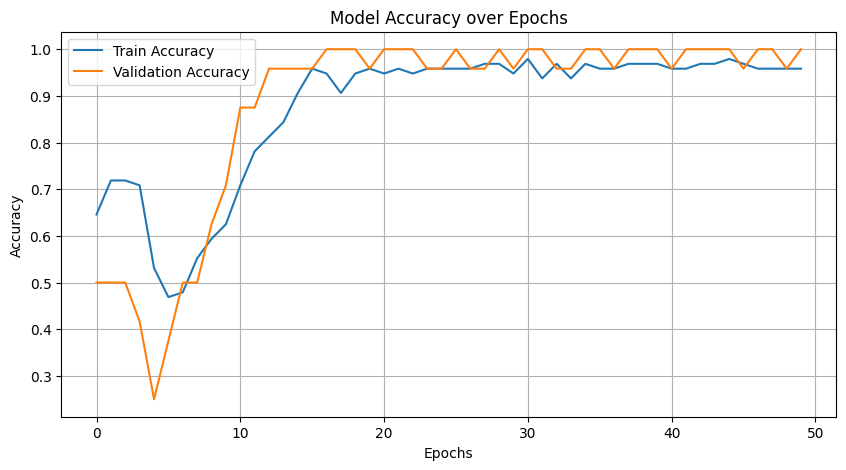

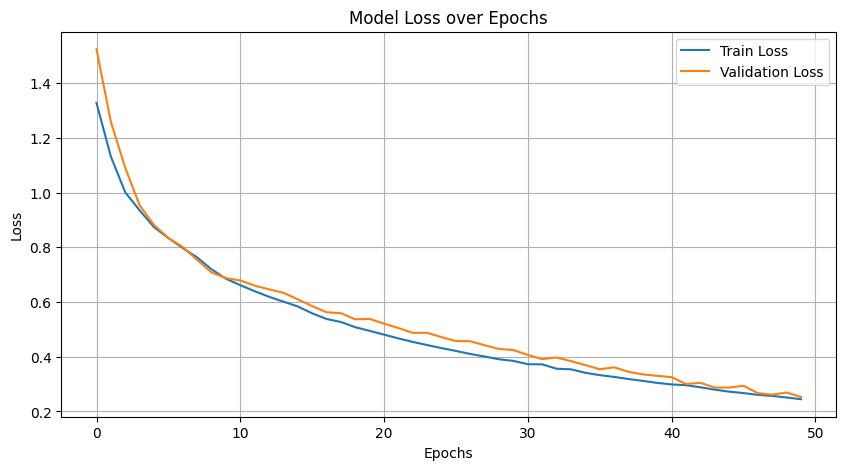

In [ ]:
# ==============================
# Building Neural Networks with TensorFlow/Keras
# ==============================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

# 1. Load dataset (Iris dataset)
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# 2. One-hot encode target
encoder = OneHotEncoder(sparse_output=False)  # updated for latest sklearn
y_encoded = encoder.fit_transform(y)

# 3. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# 4. Build Neural Network (Sequential API)
model = Sequential([
    Dense(10, input_shape=(X.shape[1],), activation='relu'),  # Hidden layer
    Dense(8, activation='relu'),                               # Hidden layer
    Dense(y_encoded.shape[1], activation='softmax')           # Output layer
])

# 5. Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Train the model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=8,
    verbose=1
)

# 7. Evaluate the model on test data
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# 8. Plot training history
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()
